# Experiment 01: Feature Transformation using PCA
**Aim:** Dimensionality reduction of Wine Dataset using Principal Component Analysis while retaining maximum variance.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Load dataset & Standardize
wine = load_wine()
X_scaled = StandardScaler().fit_transform(wine.data)

# 2. PCA with 2 Components
pca_2 = PCA(n_components=2)
X_pca = pca_2.fit_transform(X_scaled)
print(f"Explained Variance Ratio: {pca_2.explained_variance_ratio_}")
print(f"Total Variance Retained: {np.sum(pca_2.explained_variance_ratio_) * 100:.2f}%")

Explained Variance Ratio: [0.36198848 0.1920749 ]
Total Variance Retained: 55.41%


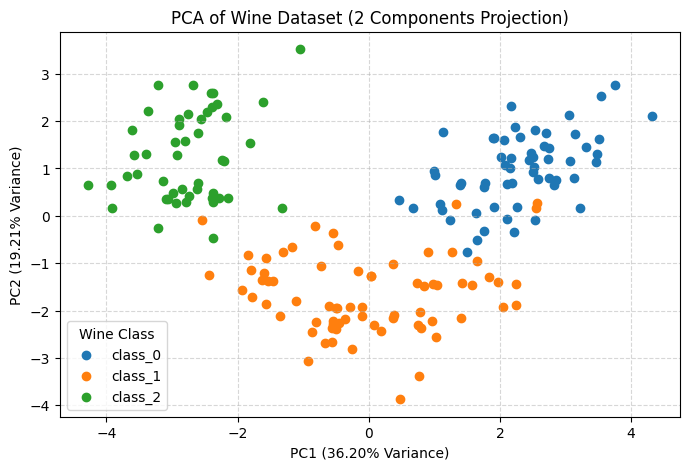

In [7]:
# 3. Scatter Plot of 2D PCA Projection
plt.figure(figsize=(8, 5))
for i, name in enumerate(wine.target_names):
    plt.scatter(X_pca[wine.target == i, 0], X_pca[wine.target == i, 1], label=name)
plt.xlabel(f"PC1 ({pca_2.explained_variance_ratio_[0]*100:.2f}% Variance)")
plt.ylabel(f"PC2 ({pca_2.explained_variance_ratio_[1]*100:.2f}% Variance)")
plt.title('PCA of Wine Dataset (2 Components Projection)')
plt.legend(title='Wine Class')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

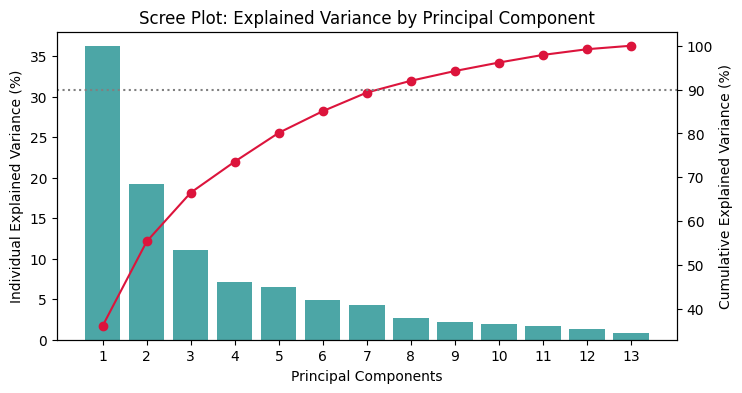

Components for >80% variance: 5
Components for >90% variance: 8


In [8]:
# 4. Scree Plot for all components
pca_full = PCA().fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_ * 100)

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(range(1, 14), pca_full.explained_variance_ratio_ * 100, alpha=0.7, color='teal', label='Individual')
ax1.set_xlabel('Principal Components')
ax1.set_ylabel('Individual Explained Variance (%)')
ax1.set_xticks(range(1, 14))

ax2 = ax1.twinx()
ax2.plot(range(1, 14), cum_var, color='crimson', marker='o', label='Cumulative')
ax2.axhline(90, color='gray', linestyle=':', label='90% Threshold')
ax2.set_ylabel('Cumulative Explained Variance (%)')
plt.title('Scree Plot: Explained Variance by Principal Component')
plt.show()

print("Components for >80% variance:", np.argmax(cum_var >= 80) + 1)
print("Components for >90% variance:", np.argmax(cum_var >= 90) + 1)